In [ ]:
from xopt import Xopt, Evaluator
from xopt.generators.scipy.latin_hypercube import LatinHypercubeGenerator
from xopt import VOCS
import numpy as np
import matplotlib.pyplot as plt

def funxtion(x, y):
    phi1 = x * (x**2 + y**2)
    phi2 = y**3 - x**2 * y + 0.5 * x
    return 0.5 * (np.sin(10.0 * phi1)**2 + np.sin(10.0 * phi2)**2)

def evaluate(inputs):
    return {"f": float(funxtion(inputs["x"], inputs["y"]))}


vocs = VOCS(variables={"x": [-1, 1], "y": [-1, 1]},
            objectives={"f": "EXPLORE"})

generator = LatinHypercubeGenerator(vocs=vocs, batch_size=2048)
evaluator=Evaluator(function=evaluate)

# This is the sampling for Latin Hypercube, gets a good spread of information across the sample space
X = Xopt(
    vocs=vocs, 
    generator=generator,
    evaluator=evaluator
)

X

/home/jmoylan/Documents/StonyBrook/AMS530/AMS-530-Principles-of-Parallel-Computing/.pixi/envs/default/lib/python3.13/site-packages/pydantic/main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Unexpected field `_sampler`: Expected `LatinHypercubeGenerator`)
  PydanticSerializationUnexpectedValue(Unexpected field `_sampler`: Expected `LatinHypercubeGenerator`)
  return self.__pydantic_serializer__.to_python(



            Xopt
________________________________
Version: 3.2.2
Data size: 0
Config as YAML:
data_dump_file: null
evaluator:
  function: __main__.evaluate
  function_kwargs: {}
  max_workers: 1
  vectorized: false
generator:
  batch_size: 2048
  name: latin_hypercube
  optimization: random-cd
  returns_id: false
  scramble: true
  seed: null
  strength: 1
  supports_batch_generation: true
  supports_constraints: true
  supports_multi_objective: true
  supports_single_objective: true
  vocs:
    constants: {}
    constraints: {}
    objectives:
      f:
        dtype: null
        type: ExploreObjective
    observables: {}
    variables:
      x:
        default_value: null
        domain:
        - -1.0
        - 1.0
        dtype: null
        type: ContinuousVariable
      y:
        default_value: null
        domain:
        - -1.0
        - 1.0
        dtype: null
        type: ContinuousVariable
serialize_inline: false
serialize_torch: false
stopping_condition: null
strict: tru

In [2]:
for _ in range(2048):
    X.step()
X.data.head()

,x,y,f,xopt_runtime,xopt_error
0,-0.740389,0.166990,0.896500,0.000025,False
1,-0.969593,-0.140402,0.087932,0.000012,False
2,-0.748875,-0.362761,0.729110,0.000010,False
3,-0.474049,0.086163,0.549378,0.000011,False
4,0.028664,-0.244658,0.000152,0.000008,False


In [ ]:
from xopt.generators.bayesian import BayesianExplorationGenerator

# 1. Redefine VOCS for minimization
vocs_opt = VOCS(
    variables={"x": [-1.0, 1.0], "y": [-1.0, 1.0]},
    objectives={"f": "EXPLORE"},
    constraints={"f": ["LESS_THAN", 0.001]}
)

ga_generator = BayesianExplorationGenerator(
    vocs=vocs_opt
)
ga_generator.n_candidates = 10

def space_filter_data(df, min_dist=0.05):
    """Filters data so no two points are closer than min_dist in parameter space."""
    kept_rows = []
    points = df[["x", "y"]].to_numpy()
    
    for i, pt in enumerate(points):
        if not kept_rows:
            kept_rows.append(i)
            continue
        
        # Distance to previously accepted points
        dists = np.linalg.norm(points[kept_rows] - pt, axis=1)
        if np.all(dists >= min_dist):
            kept_rows.append(i)
            
    return df.iloc[kept_rows]

filtered_data = space_filter_data(X.data, min_dist=0.05)

X_opt = Xopt(
    vocs=vocs_opt,
    generator=ga_generator,
    evaluator=evaluator,
    data=filtered_data
)

for i in range(10):
    X_opt.generator.train_model()
    X_opt.step()

/home/jmoylan/Documents/StonyBrook/AMS530/AMS-530-Principles-of-Parallel-Computing/.pixi/envs/default/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Iteration 1
Iteration 2
Iteration 3
Iteration 4
Iteration 5
Iteration 6
Iteration 7
Iteration 8
Iteration 9
Iteration 10


,x,y,f,xopt_runtime,xopt_error
0,-0.740389,0.166990,0.896500,0.000025,False
1,-0.969593,-0.140402,0.087932,0.000012,False
2,-0.748875,-0.362761,0.729110,0.000010,False
3,-0.474049,0.086163,0.549378,0.000011,False
4,0.028664,-0.244658,0.000152,0.000008,False


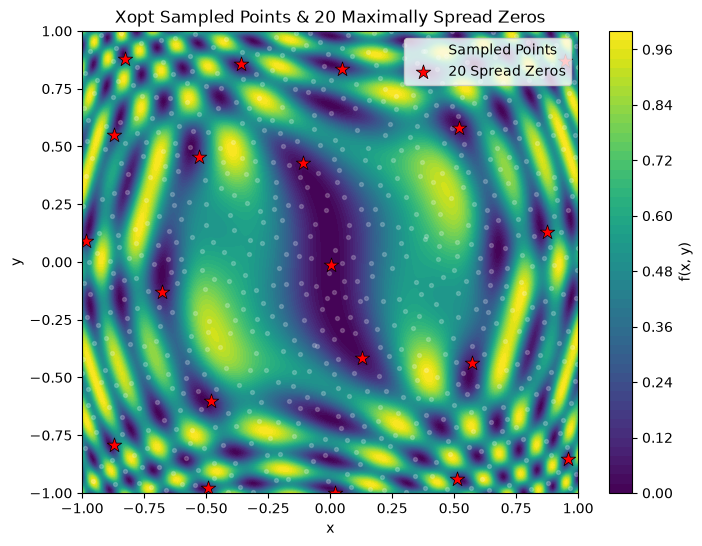

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

def select_maxmin_dispersion(candidates, k=20):
    """Selects k points from candidates that are maximally spread apart."""
    if len(candidates) <= k:
        return candidates

    # 1. Start with the candidate point closest to a corner or boundary
    selected_indices = [0]
    
    # 2. Distance matrix between all candidates
    dist_matrix = cdist(candidates, candidates)
    min_dists = dist_matrix[:, selected_indices[0]]

    # 3. Iteratively pick the candidate farthest from all previously selected points
    for _ in range(1, k):
        next_idx = np.argmax(min_dists)
        selected_indices.append(next_idx)
        min_dists = np.minimum(min_dists, dist_matrix[:, next_idx])

    return candidates[selected_indices]


df = X_opt.data

threshold = 0.005  # adjust threshold if needed based on evaluated data
candidate_zeros = df[df["f"] < threshold][["x", "y"]].to_numpy()

if len(candidate_zeros) < 30:
    candidate_zeros = df.nsmallest(100, "f")[["x", "y"]].to_numpy()

spread_20_zeros = select_maxmin_dispersion(candidate_zeros, k=20)


fig, ax = plt.subplots(figsize=(8, 6))

# Background contour plot
x_grid = np.linspace(-1, 1, 250)
y_grid = np.linspace(-1, 1, 250)
XX, YY = np.meshgrid(x_grid, y_grid)
ZZ = funxtion(XX, YY)

contour = ax.contourf(XX, YY, ZZ, levels=50, cmap="viridis")
plt.colorbar(contour, label="f(x, y)")

# Plot all sampled points as small translucent dots
ax.scatter(df["x"], df["y"], c="white", alpha=0.2, s=8, label="Sampled Points")

# Plot the 20 maximally separated zeros
ax.scatter(
    spread_20_zeros[:, 0], 
    spread_20_zeros[:, 1], 
    c="red", 
    marker="*", 
    s=120, 
    edgecolors="black",
    linewidths=0.5,
    label="20 Spread Zeros"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Xopt Sampled Points & 20 Maximally Spread Zeros")
ax.legend(loc="upper right")
plt.show()